In [1]:
pip install scikit-learn pandas numpy matplotlib shap PyALE treeinterpreter

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [PyALE]


Model trained successfully!


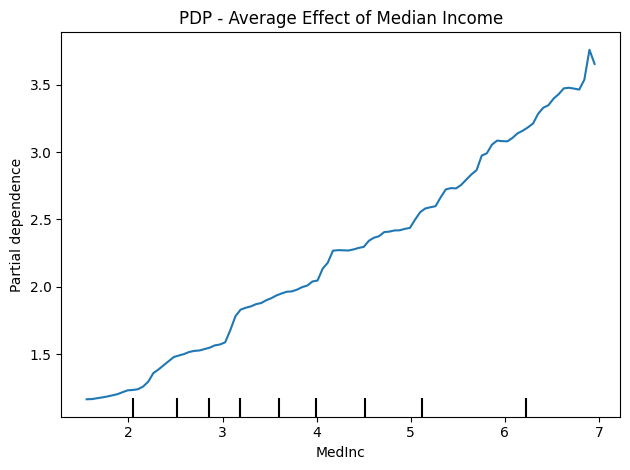

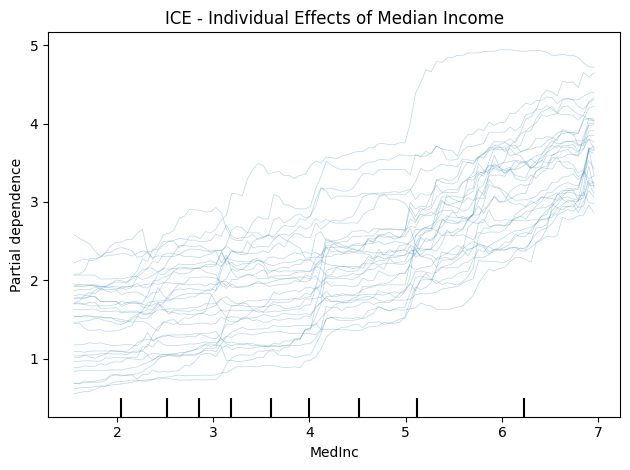

INFO:PyALE._ALE_generic:Continuous feature detected.


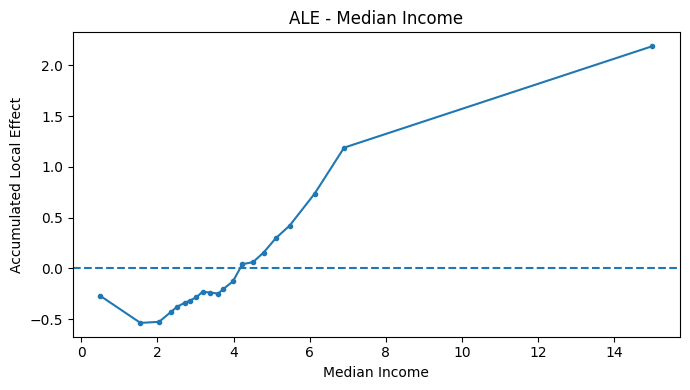

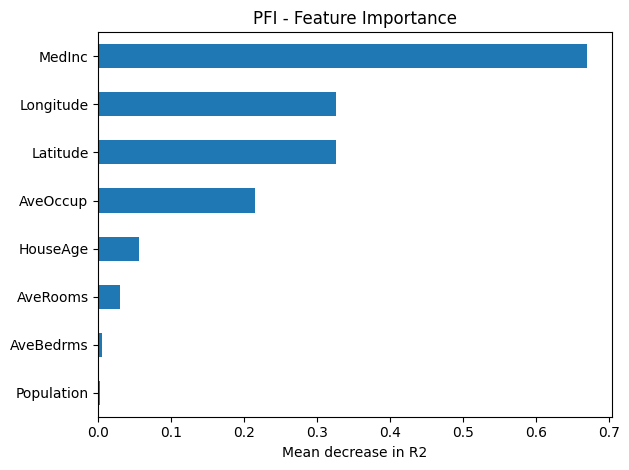

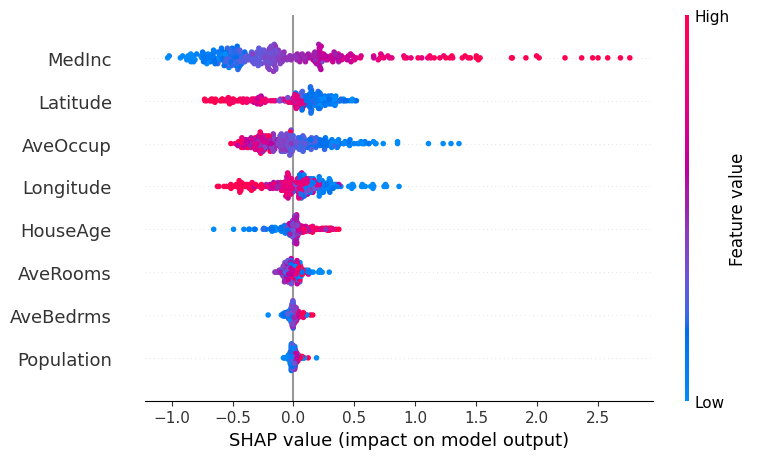

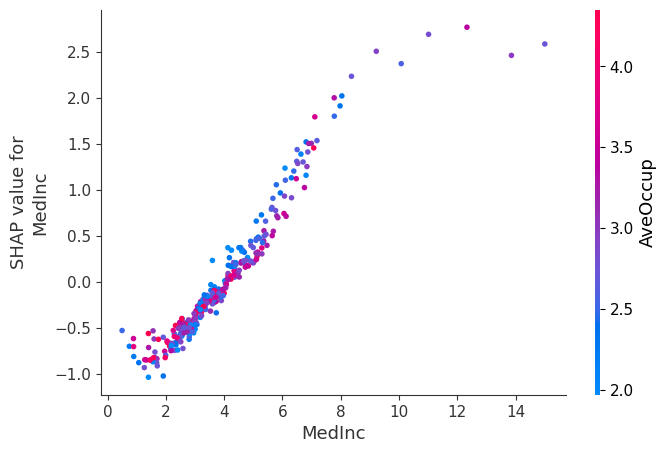

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWarning: X has feature names, but DecisionTreeRegressor was fitted without feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2732: UserWa

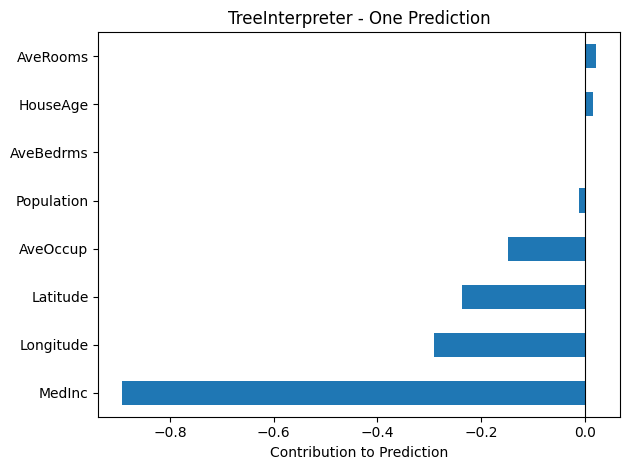


Actual value: 0.477
Predicted value: [0.53374]
Baseline value: 2.072139109108513

Feature contributions:
MedInc       -0.892709
Longitude    -0.290192
Latitude     -0.235979
AveOccup     -0.147869
AveRooms      0.022236
HouseAge      0.015631
Population   -0.010899
AveBedrms     0.001381
dtype: float64


In [2]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import (
    PartialDependenceDisplay,
    permutation_importance
)

# ==================================================
# 1. LOAD DATA AND TRAIN MODEL
# ==================================================

data = fetch_california_housing(as_frame=True)
X = data.data
y = data.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

model = RandomForestRegressor(
    n_estimators=50, random_state=42, n_jobs=-1
)
model.fit(X_train, y_train)

# Use a smaller test sample to make explanations faster
X_sample = X_test.sample(
    n=min(300, len(X_test)), random_state=42
)

print("Model trained successfully!")


# ==================================================
# 2. PDP - PARTIAL DEPENDENCE PLOT
# ==================================================

PartialDependenceDisplay.from_estimator(
    model, X_sample, ["MedInc"], kind="average"
)
plt.title("PDP - Average Effect of Median Income")
plt.tight_layout()
plt.show()


# ==================================================
# 3. ICE - INDIVIDUAL CONDITIONAL EXPECTATION
# ==================================================

PartialDependenceDisplay.from_estimator(
    model, X_sample, ["MedInc"], kind="individual",
    subsample=30, random_state=42
)
plt.title("ICE - Individual Effects of Median Income")
plt.tight_layout()
plt.show()


# ==================================================
# 4. ALE - ACCUMULATED LOCAL EFFECTS
# ==================================================

# Requires: pip install PyALE
from PyALE import ale

ale_result = ale(
    X=X_sample,
    model=model,
    feature=["MedInc"],
    grid_size=20,
    include_CI=False,
    plot=False
)

plt.figure(figsize=(7, 4))
plt.plot(ale_result.index, ale_result["eff"], marker=".")
plt.axhline(0, linestyle="--")
plt.xlabel("Median Income")
plt.ylabel("Accumulated Local Effect")
plt.title("ALE - Median Income")
plt.tight_layout()
plt.show()


# ==================================================
# 5. PFI - PERMUTATION FEATURE IMPORTANCE
# ==================================================

pfi = permutation_importance(
    model, X_sample, y_test.loc[X_sample.index],
    scoring="r2", n_repeats=5, random_state=42
)

importance = pd.Series(
    pfi.importances_mean, index=X.columns
).sort_values()

importance.tail(10).plot(kind="barh")
plt.xlabel("Mean decrease in R2")
plt.title("PFI - Feature Importance")
plt.tight_layout()
plt.show()


# ==================================================
# 6. SHAP - GLOBAL IMPACT AND DEPENDENCE
# ==================================================

# Requires: pip install shap
import shap

explainer = shap.TreeExplainer(model)
shap_values = explainer.shap_values(X_sample)

# Global feature impact
shap.summary_plot(shap_values, X_sample)

# Median income dependence
shap.dependence_plot(
    "MedInc", shap_values, X_sample
)


# ==================================================
# 7. TREEINTERPRETER - ONE PREDICTION
# ==================================================

# Requires: pip install treeinterpreter
from treeinterpreter import treeinterpreter as ti

one_sample = X_test.iloc[[0]]

prediction, bias, contributions = ti.predict(
    model, one_sample
)

contributions = np.asarray(contributions).reshape(-1)

contribution_series = pd.Series(
    contributions, index=X.columns
)
top_contributions = contribution_series.loc[
    contribution_series.abs().sort_values(
        ascending=False
    ).head(10).index
].sort_values()

top_contributions.plot(kind="barh")
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Contribution to Prediction")
plt.title("TreeInterpreter - One Prediction")
plt.tight_layout()
plt.show()

print("\nActual value:", y_test.loc[one_sample.index[0]])
print("Predicted value:", prediction[0])
print("Baseline value:", np.asarray(bias).reshape(-1)[0])
print("\nFeature contributions:")
print(top_contributions.sort_values(
    key=abs, ascending=False
))


In [6]:
pip install torch torchvision captum lime scikit-image matplotlib pillow numpy saliency

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
  Created wheel for lime: filename=lime-0.2.0.1-py3-none-any.whl size=283913 sha256=a923dda8b42c24d95ecf0136eab93251f5a32a2ae58ccbe34ceb5d857634387d
  Stored in directory: /root/.cache/pip/wheels/7c/04/5c/157dc9106512a6c7a30653ec064490c94a49e0fc8f63d19ab9
Successfully built lime
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [captum]


Predicted class: tabby


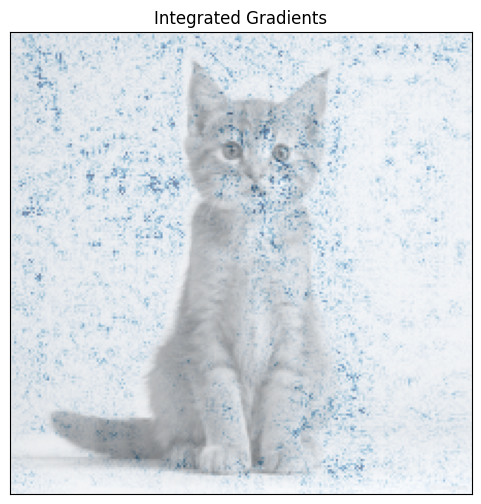

Integrated Gradients completed


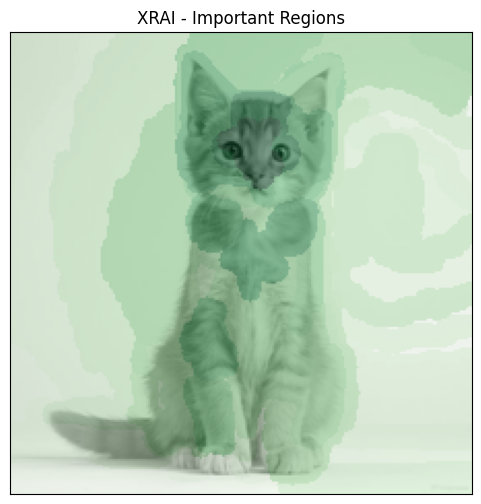

XRAI completed


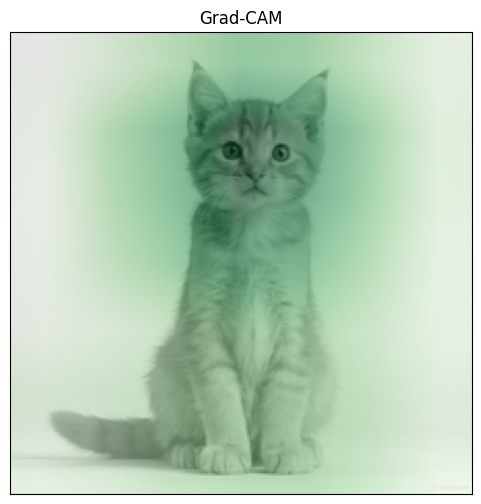

Grad-CAM completed


  0%|          | 0/500 [00:00<?, ?it/s]

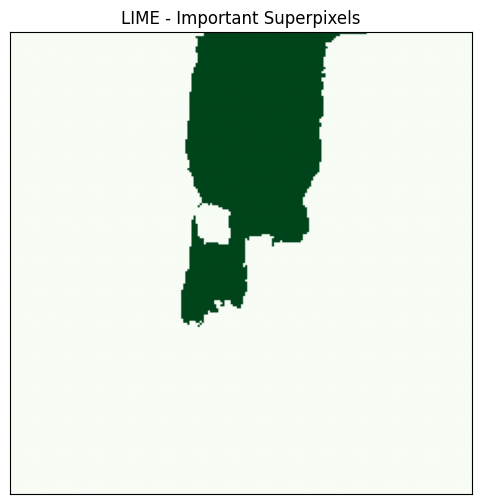

LIME completed


/usr/local/lib/python3.13/dist-packages/captum/attr/_core/guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


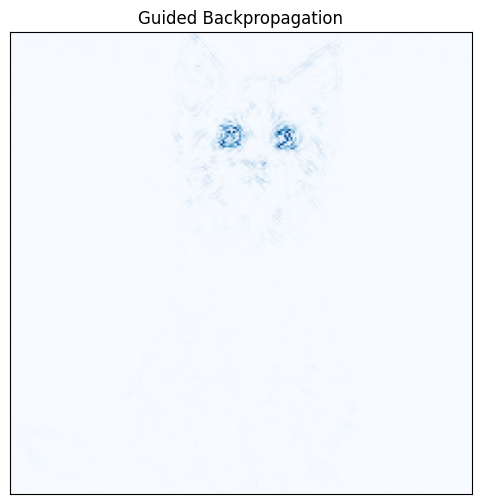

Guided Backpropagation completed


/usr/local/lib/python3.13/dist-packages/captum/attr/_core/guided_backprop_deconvnet.py:66: UserWarning: Setting backward hooks on ReLU activations.The hooks will be removed after the attribution is finished
  warnings.warn(


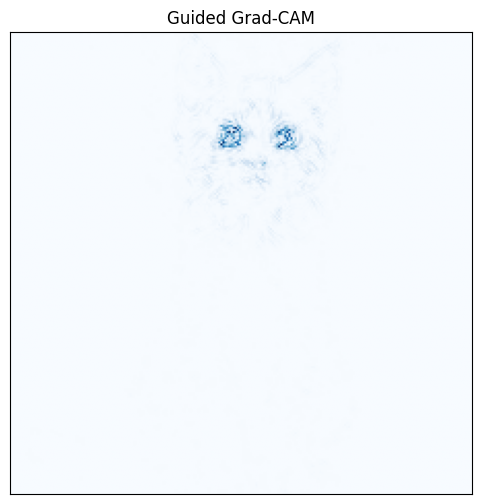

Guided Grad-CAM completed
All six explanations generated!


In [9]:

import numpy as np
import torch
import torch.nn.functional as F

from PIL import Image
from torchvision import models

from captum.attr import (
    IntegratedGradients,
    LayerGradCam,
    LayerAttribution,
    GuidedBackprop,
    GuidedGradCam,
    visualization as viz
)

from lime.lime_image import LimeImageExplainer
import saliency.core as saliency


# ==========================================
# 1. LOAD IMAGE AND MODEL
# ==========================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

weights = models.ResNet18_Weights.DEFAULT
model = models.resnet18(weights=weights).to(device)
model.eval()

preprocess = weights.transforms()

image = Image.open("/content/cat.jpg").convert("RGB").resize((224, 224))
image_np = np.asarray(image).astype(np.float32) / 255.0

input_tensor = preprocess(image).unsqueeze(0).to(device)
input_tensor.requires_grad_(True)

with torch.no_grad():
    output = model(input_tensor)
    predicted_class = output.argmax(dim=1).item()

print("Predicted class:", weights.meta["categories"][predicted_class])


# ==========================================
# COMMON VISUALIZATION FUNCTION
# ==========================================

def plot_attr(attr, title, sign="absolute_value",
              method="blended_heat_map", original=image_np):

    if isinstance(attr, torch.Tensor):
        attr = attr.detach().cpu().squeeze().numpy()

    # Convert CHW attribution to HWC if necessary
    if attr.ndim == 3 and attr.shape[0] in (1, 3):
        attr = np.transpose(attr, (1, 2, 0))

    if attr.ndim == 3 and attr.shape[-1] == 1:
        attr = attr.squeeze(-1)

    viz.visualize_image_attr(
        attr,
        original_image=original,
        method=method,
        sign=sign,
        title=title,
        show_colorbar=False,
        use_pyplot=True
    )


# ==========================================
# 2. INTEGRATED GRADIENTS
# ==========================================

ig = IntegratedGradients(model)

ig_attr = ig.attribute(
    input_tensor,
    baselines=torch.zeros_like(input_tensor),
    target=predicted_class,
    n_steps=30
)

plot_attr(ig_attr, "Integrated Gradients")
print("Integrated Gradients completed")


# ==========================================
# 3. XRAI
# ==========================================

def call_model_function(
    images, call_model_args=None, expected_keys=None
):
    # XRAI supplies images in NHWC format, range [0, 1]
    x = torch.tensor(
        images, dtype=torch.float32, device=device
    ).permute(0, 3, 1, 2).requires_grad_(True)

    mean = torch.tensor(
        [0.485, 0.456, 0.406], device=device
    ).view(1, 3, 1, 1)

    std = torch.tensor(
        [0.229, 0.224, 0.225], device=device
    ).view(1, 3, 1, 1)

    logits = model((x - mean) / std)
    target = call_model_args["target"]

    gradients = torch.autograd.grad(
        logits[:, target].sum(), x
    )[0]

    return {
        saliency.base.INPUT_OUTPUT_GRADIENTS:
            gradients.permute(0, 2, 3, 1).detach().cpu().numpy()
    }


xrai = saliency.XRAI()

xrai_attr = xrai.GetMask(
    image_np,
    call_model_function,
    {"target": predicted_class}
)

plot_attr(
    xrai_attr,
    "XRAI - Important Regions",
    sign="positive",
    method="blended_heat_map"
)

print("XRAI completed")


# ==========================================
# 4. GRAD-CAM
# ==========================================

target_layer = model.layer4[-1]

gradcam = LayerGradCam(model, target_layer)

cam_attr = gradcam.attribute(
    input_tensor,
    target=predicted_class,
    relu_attributions=True
)

cam_attr = LayerAttribution.interpolate(
    cam_attr,
    input_tensor.shape[2:],
    interpolate_mode="bilinear"
)

plot_attr(
    cam_attr,
    "Grad-CAM",
    sign="positive"
)

print("Grad-CAM completed")


# ==========================================
# 5. LIME FOR IMAGES
# ==========================================

def predict_for_lime(images):
    batch = torch.stack([
        preprocess(Image.fromarray(img.astype(np.uint8)))
        for img in images
    ]).to(device)

    with torch.no_grad():
        return F.softmax(model(batch), dim=1).cpu().numpy()


lime_explainer = LimeImageExplainer()

lime_exp = lime_explainer.explain_instance(
    (image_np * 255).astype(np.uint8),
    predict_for_lime,
    top_labels=1,
    num_samples=500
)

lime_image, lime_mask = lime_exp.get_image_and_mask(
    predicted_class,
    positive_only=True,
    num_features=5,
    hide_rest=False
)

plot_attr(
    lime_mask.astype(float),
    "LIME - Important Superpixels",
    sign="positive",
    method="heat_map",
    original=lime_image.astype(np.float32) / 255.0
)


print("LIME completed")


# ==========================================
# 6. GUIDED BACKPROPAGATION
# ==========================================

guided_bp = GuidedBackprop(model)

gb_attr = guided_bp.attribute(
    input_tensor,
    target=predicted_class
)

plot_attr(
    gb_attr,
    "Guided Backpropagation",
    sign="absolute_value",
    method="heat_map",
    original=None
)

print("Guided Backpropagation completed")


# ==========================================
# 7. GUIDED GRAD-CAM
# ==========================================

guided_gc = GuidedGradCam(model, target_layer)

ggc_attr = guided_gc.attribute(
    input_tensor,
    target=predicted_class
)

plot_attr(
    ggc_attr,
    "Guided Grad-CAM",
    sign="absolute_value",
    method="heat_map",
    original=None
)

print("Guided Grad-CAM completed")
print("All six explanations generated!")


In [10]:
pip install torch transformers captum lime matplotlib numpy

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

Text: The movie was wonderful, exciting and enjoyable.
Predicted sentiment: POSITIVE
Probabilities: [1.1245082e-04 9.9988759e-01]

Tokens:
['[CLS]', 'the', 'movie', 'was', 'wonderful', ',', 'exciting', 'and', 'enjoyable', '.', '[SEP]']


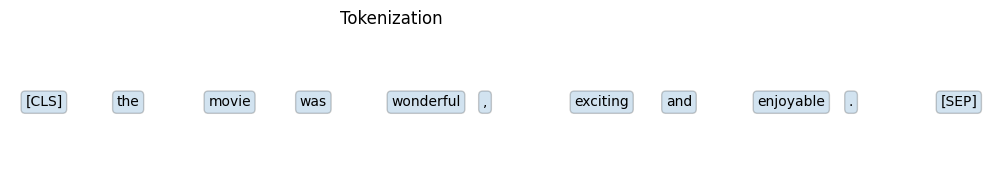


Embedding shape: (1, 11, 768)


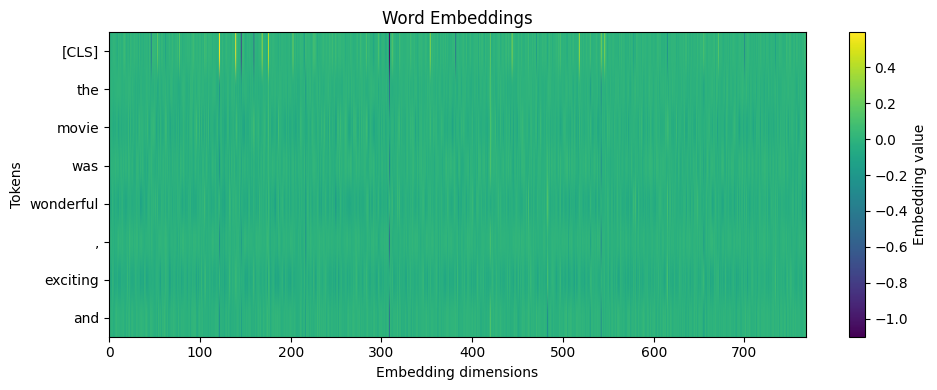


LIME explanation:
enjoyable 0.0203
wonderful 0.0198
exciting 0.0183
was -0.0115
and 0.0091
movie 0.0063
The -0.0048


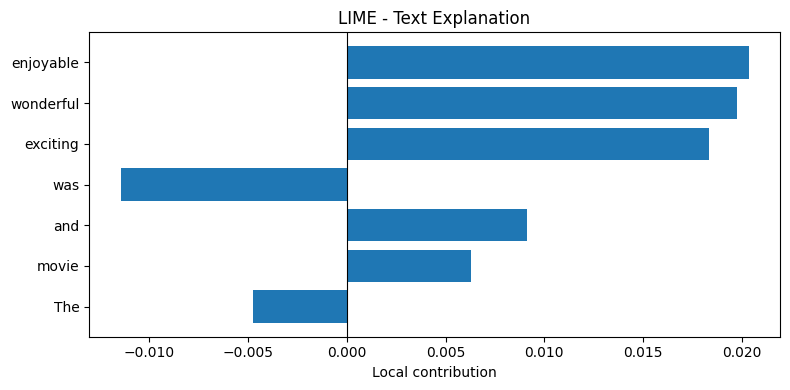


Gradient x Input scores:
[CLS] 0.0054
the -0.0049
movie -0.0022
was 0.0002
wonderful 0.0108
, 0.0029
exciting 0.0086
and 0.0035
enjoyable 0.0032
. -0.0011
[SEP] -0.0036


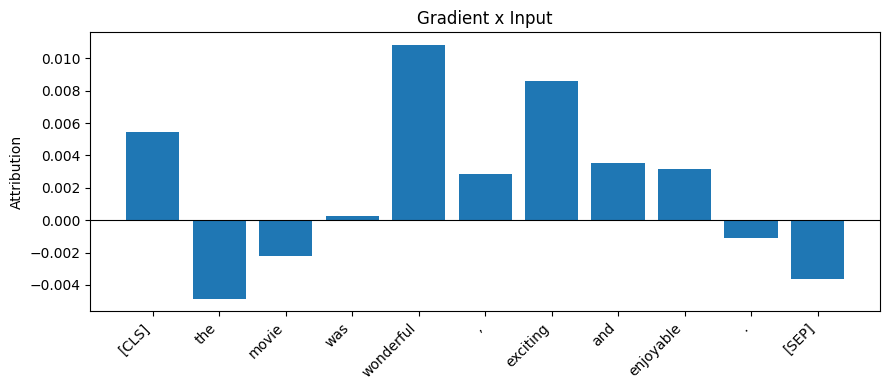


Layer Integrated Gradients scores:
[CLS] 0.2211
the 0.079
movie 0.1846
was 0.0793
wonderful 0.6654
, 0.1502
exciting 0.5333
and 0.252
enjoyable 0.9176
. 0.2019
[SEP] 1.7232


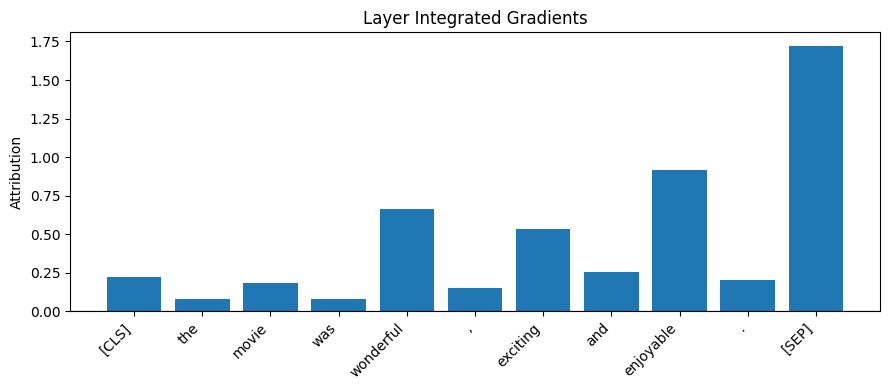


All five text XAI demonstrations completed!

All five text XAI demonstrations completed!


In [13]:

import numpy as np
import torch
import matplotlib.pyplot as plt

from transformers import AutoTokenizer, AutoModelForSequenceClassification
from captum.attr import LayerIntegratedGradients, InputXGradient
from lime.lime_text import LimeTextExplainer

# ==========================================
# 1. LOAD PRETRAINED MODEL
# ==========================================

MODEL_NAME = "distilbert/distilbert-base-uncased-finetuned-sst-2-english"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME
).to(device)

model.eval()

text = "The movie was wonderful, exciting and enjoyable."

inputs = tokenizer(
    text,
    return_tensors="pt",
    truncation=True,
    max_length=128
).to(device)

input_ids = inputs["input_ids"]
attention_mask = inputs["attention_mask"]

with torch.no_grad():
    logits = model(**inputs).logits
    probabilities = torch.softmax(logits, dim=1)[0]

predicted_class = int(probabilities.argmax().item())
class_names = ["NEGATIVE", "POSITIVE"]

print("Text:", text)
print("Predicted sentiment:", class_names[predicted_class])
print("Probabilities:", probabilities.cpu().numpy())


# ==========================================
# 2. TOKENIZATION
# ==========================================

tokens = tokenizer.convert_ids_to_tokens(input_ids[0].tolist())

print("\nTokens:")
print(tokens)

plt.figure(figsize=(10, 2))
plt.axis("off")

for i, token in enumerate(tokens):
    plt.text(
        0.02 + i * 0.12, 0.5, token,
        fontsize=10,
        bbox=dict(boxstyle="round", alpha=0.2)
    )

plt.title("Tokenization")
plt.tight_layout()
plt.show()


# ==========================================
# 3. WORD EMBEDDINGS
# ==========================================

embedding_layer = model.get_input_embeddings()

with torch.no_grad():
    embeddings = embedding_layer(input_ids)

print("\nEmbedding shape:", tuple(embeddings.shape))

embedding_values = embeddings[
    0, :min(8, len(tokens)), :
].detach().cpu().numpy()

plt.figure(figsize=(10, 4))
plt.imshow(embedding_values, aspect="auto", cmap="viridis")
plt.xlabel("Embedding dimensions")
plt.ylabel("Tokens")
plt.yticks(
    range(min(8, len(tokens))),
    tokens[:8]
)
plt.title("Word Embeddings")
plt.colorbar(label="Embedding value")
plt.tight_layout()
plt.show()


# ==========================================
# 4. LIME FOR TEXT
# ==========================================

def predict_proba(texts):
    batch = tokenizer(
        list(texts),
        padding=True,
        truncation=True,
        max_length=128,
        return_tensors="pt"
    ).to(device)

    with torch.no_grad():
        output = model(**batch).logits
        return torch.softmax(output, dim=1).cpu().numpy()


lime_explainer = LimeTextExplainer(class_names=class_names)

lime_exp = lime_explainer.explain_instance(
    text,
    predict_proba,
    num_features=8,
    num_samples=500
)

lime_values = lime_exp.as_list(label=predicted_class)

print("\nLIME explanation:")
for word, score in lime_values:
    print(word, round(score, 4))

words = [item[0] for item in lime_values]
scores = [item[1] for item in lime_values]

plt.figure(figsize=(8, 4))
plt.barh(words[::-1], scores[::-1])
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Local contribution")
plt.title("LIME - Text Explanation")
plt.tight_layout()
plt.show()


# ==========================================
# COMMON FORWARD FUNCTION
# ==========================================

def forward_from_embeddings(embeds, mask):
    return model(
        inputs_embeds=embeds,
        attention_mask=mask
    ).logits


# ==========================================
# 5. GRADIENT x INPUT
# ==========================================

word_embeddings = embedding_layer(input_ids).detach()
word_embeddings.requires_grad_(True)

gradient_x_input = InputXGradient(forward_from_embeddings)

gxi_attr = gradient_x_input.attribute(
    word_embeddings,
    additional_forward_args=(attention_mask,),
    target=predicted_class
)

gxi_scores = gxi_attr.sum(dim=-1)[0].detach().cpu().numpy()

print("\nGradient x Input scores:")
for token, score in zip(tokens, gxi_scores):
    print(token, round(float(score), 4))

plt.figure(figsize=(9, 4))
plt.bar(range(len(tokens)), gxi_scores)
plt.xticks(range(len(tokens)), tokens, rotation=45, ha="right")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Attribution")
plt.title("Gradient x Input")
plt.tight_layout()
plt.show()


# ==========================================
# 6. LAYER INTEGRATED GRADIENTS
# ==========================================

# ==========================================
# 6. LAYER INTEGRATED GRADIENTS (CORRECTED)
# ==========================================

# Explain the output of the first Transformer layer
target_layer = model.distilbert.transformer.layer[0]

lig = LayerIntegratedGradients(
    forward_from_embeddings,
    target_layer
)

# Baseline: PAD-token embeddings
baseline_ids = torch.full_like(
    input_ids, tokenizer.pad_token_id
)

input_embeddings = embedding_layer(input_ids)
baseline_embeddings = embedding_layer(baseline_ids)

lig_attr = lig.attribute(
    inputs=input_embeddings,
    baselines=baseline_embeddings,
    additional_forward_args=(attention_mask,),
    target=predicted_class,
    n_steps=20
)

# Convert attribution to one score per token
lig_scores = lig_attr.sum(dim=-1)[0].detach().cpu().numpy()

print("\nLayer Integrated Gradients scores:")
for token, score in zip(tokens, lig_scores):
    print(token, round(float(score), 4))

plt.figure(figsize=(9, 4))
plt.bar(range(len(tokens)), lig_scores)
plt.xticks(range(len(tokens)), tokens, rotation=45, ha="right")
plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Attribution")
plt.title("Layer Integrated Gradients")
plt.tight_layout()
plt.show()

print("\nAll five text XAI demonstrations completed!")

print("\nAll five text XAI demonstrations completed!")
